# AAPL | Data Processing & GAN Preparation (2025–2026)

**Rebuild of the uploaded Stock Price Data Processing and Analysis notebook**, retaining: close-price plot; MA7, MA21, MACD, 20SD, Bollinger upper/lower, EMA, logmomentum; Fourier components (3/6/9) and their plots; technical-indicator plots. Also adds the supplied Finaldata feature schema, FinBERT daily sentiment merge, next-day targets, chronological split, training-only scaling, sliding windows, and GAN `.npy`/`.pkl` exports.

**Data provenance:** Yahoo Finance Chart JSON API (the endpoint that worked for you). News sentiment comes from your supplied FinBERT-scored CSV; this notebook does **not** claim to fetch or run FinBERT on new articles. When Yahoo is unavailable, use the uploaded `Finaldata_2025_2026.csv` as a **price-only offline fallback**; derived features are still recomputed. FFT over the entire series is **exploratory only**, not an input feature (it leaks future information). With only ~1 year of daily observations, GAN estimates may be unstable.


In [37]:
import os, json, pickle, warnings
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()

START_DATE = "2025-10-09"
END_DATE = "2026-10-09"
SYMBOL = "AAPL"

NEWS_FILE = (
    ROOT.parent
    / "data"
    / "raw"
    / "aapl_news_finbert_2025_2026.csv"
)

OFFLINE_FILE = ROOT / "Finaldata_2025_2026.csv"

OUT = ROOT / "gan_ready"
OUT.mkdir(exist_ok=True)

LOOKBACK = 20
TEST_FRACTION = 0.20
USE_OFFLINE_FALLBACK = True

np.random.seed(42)

print("Working directory:", ROOT)
print("News file:", NEWS_FILE)
print("News file exists:", NEWS_FILE.exists())

Working directory: /Users/my/Desktop/TWO-LSTM/FinBert_LSTMGRU_GAN/finbert/notebooks
News file: /Users/my/Desktop/TWO-LSTM/FinBert_LSTMGRU_GAN/finbert/data/raw/aapl_news_finbert_2025_2026.csv
News file exists: True


## 1 · Download daily OHLCV using the working Yahoo Chart API

In [38]:
import requests

def fetch_yahoo_chart(symbol=SYMBOL, start_date=START_DATE, end_date=END_DATE):
    # The API end boundary is exclusive. Use next calendar day.
    start = int(pd.Timestamp(start_date, tz='UTC').timestamp())
    end = int((pd.Timestamp(end_date, tz='UTC') + pd.Timedelta(days=1)).timestamp())
    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{symbol}"
    resp = requests.get(url, params={'period1':start, 'period2':end, 'interval':'1d'},
                        headers={'User-Agent':'Mozilla/5.0', 'Accept':'application/json'}, timeout=30)
    resp.raise_for_status()
    if 'json' not in resp.headers.get('Content-Type','').lower():
        raise ValueError('Yahoo did not return JSON; possibly a verification page')
    payload = resp.json()
    if payload.get('chart',{}).get('error'):
        raise ValueError(str(payload['chart']['error']))
    result = payload['chart']['result'][0]
    quote = result['indicators']['quote'][0]
    dates = pd.to_datetime(result['timestamp'], unit='s', utc=True).tz_convert('America/New_York').date
    df = pd.DataFrame({'Date':pd.to_datetime(dates), 'Open':quote['open'], 'High':quote['high'],
                       'Low':quote['low'], 'Close':quote['close'], 'Volume':quote['volume']})
    adj = result['indicators'].get('adjclose')
    df['Adj_Close'] = adj[0]['adjclose'] if adj else df['Close']
    return df

try:
    prices = fetch_yahoo_chart()
    SOURCE = 'Yahoo Finance Chart API'
except (requests.RequestException, ValueError, KeyError, IndexError, TypeError) as exc:
    if not USE_OFFLINE_FALLBACK or not OFFLINE_FILE.exists():
        raise RuntimeError('Price download failed. Put Finaldata_2025_2026.csv next to notebook for offline fallback.') from exc
    warnings.warn(f'Yahoo unavailable ({exc}); using OHLCV columns from local Finaldata CSV')
    prices = pd.read_csv(OFFLINE_FILE, parse_dates=['Date'])
    SOURCE = 'Offline reference CSV (OHLCV only)'

required = ['Date','Open','High','Low','Close','Volume','Adj_Close']
if not set(required).issubset(prices.columns):
    raise ValueError(f'Missing required price columns: {set(required)-set(prices.columns)}')
prices = prices[required].copy()
prices['Date'] = pd.to_datetime(prices['Date']).dt.normalize()
for c in required[1:]: prices[c] = pd.to_numeric(prices[c], errors='coerce')
prices = prices.loc[prices.Date.between(START_DATE, END_DATE)].dropna(subset=['Close','Adj_Close'])
prices = prices.sort_values('Date').drop_duplicates('Date').reset_index(drop=True)
assert len(prices) > 50, 'Too few rows for meaningful windows'
print('Source:', SOURCE, '| Rows:',len(prices), '|',prices.Date.min().date(), 'to',prices.Date.max().date())
display(prices.head())


Source: Yahoo Finance Chart API | Rows: 252 | 2025-10-09 to 2026-10-09


,Date,Open,High,Low,Close,Volume,Adj_Close
0,2025-10-09,257.809998,258.000000,253.139999,254.039993,38322000,253.105026
1,2025-10-10,254.940002,256.380005,244.000000,245.270004,61999100,244.367325
2,2025-10-13,249.380005,249.690002,245.559998,247.660004,38142900,246.748520
3,2025-10-14,246.600006,248.850006,244.699997,247.770004,35478000,246.858109
4,2025-10-15,249.490005,251.820007,247.470001,249.339996,33893600,248.422333


## 2 · Original close-price chart

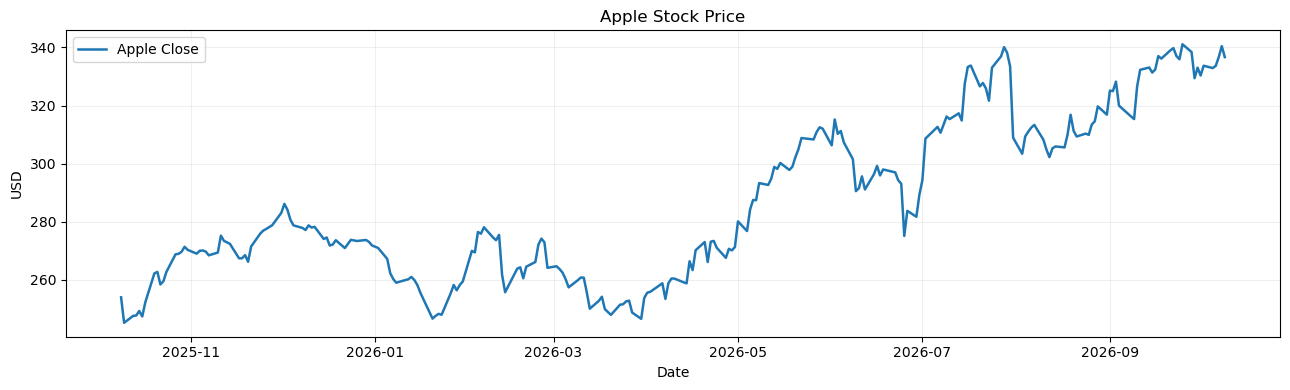

In [39]:
fig, ax = plt.subplots(figsize=(13,4))
ax.plot(prices['Date'], prices['Close'], label='Apple Close', lw=1.8)
ax.set(xlabel='Date', ylabel='USD', title='Apple Stock Price')
ax.xaxis.set_major_formatter(DateFormatter('%Y-%m'))
ax.legend(); ax.grid(alpha=.2); plt.tight_layout(); plt.show()


## 3 · All original technical indicators + extended modeling features

In [40]:
def get_technical_indicators(data):
    d = data.copy()
    close = d['Close']
    adj = d['Adj_Close']
    # Original notebook features, retaining its Close-based definitions
    d['MA7'] = close.rolling(7).mean()
    d['MA21'] = close.rolling(21).mean()
    d['MACD'] = close.ewm(span=12, adjust=False).mean() - close.ewm(span=26, adjust=False).mean()
    d['20SD'] = close.rolling(20).std()
    d['upper_band'] = d['MA21'] + 2*d['20SD']
    d['lower_band'] = d['MA21'] - 2*d['20SD']
    d['EMA'] = close.ewm(com=.5).mean()
    d['logmomentum'] = np.log(close / close.shift(1))
    # Supplied Finaldata-style features, using adjusted close consistently
    d['Log_Return'] = np.log(adj).diff()
    d['EMA12'] = adj.ewm(span=12, adjust=False).mean()
    d['EMA26'] = adj.ewm(span=26, adjust=False).mean()
    d['MACD_Signal'] = (d['EMA12']-d['EMA26']).ewm(span=9, adjust=False).mean()
    d['SD20'] = adj.rolling(20).std()
    d['Volatility20'] = d['Log_Return'].rolling(20).std()
    d['Volume_Log'] = np.log1p(d['Volume'].clip(lower=0))
    delta = adj.diff(); gain = delta.clip(lower=0); loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
    avg_loss = loss.ewm(alpha=1/14, adjust=False, min_periods=14).mean()
    rs = avg_gain / avg_loss.replace(0,np.nan)
    d['RSI14'] = (100-100/(1+rs)).where(avg_loss.ne(0), 100)
    d.loc[(avg_loss==0)&(avg_gain==0), 'RSI14'] = 50
    adj_ma7 = adj.rolling(7).mean(); adj_ma21 = adj.rolling(21).mean()
    d['MA7_Ratio'] = adj / adj_ma7 - 1
    d['MA21_Ratio'] = adj / adj_ma21 - 1
    d['MACD_Ratio'] = (d['EMA12']-d['EMA26']) / adj
    return d

T_df = get_technical_indicators(prices)
# Original notebook removes first 20 rows (MA21 warm-up)
dataset = T_df.iloc[20:].reset_index(drop=True)
print('Technical columns:', T_df.columns.tolist())


Technical columns: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Adj_Close', 'MA7', 'MA21', 'MACD', '20SD', 'upper_band', 'lower_band', 'EMA', 'logmomentum', 'Log_Return', 'EMA12', 'EMA26', 'MACD_Signal', 'SD20', 'Volatility20', 'Volume_Log', 'RSI14', 'MA7_Ratio', 'MA21_Ratio', 'MACD_Ratio']


## 4 · Fourier transform: preserve the original 3/6/9 components (exploration only)

In [41]:
def get_fourier_transfer(dataset):
    close_fft = np.fft.fft(dataset['Close'].to_numpy(dtype=float))
    fft_com_df = pd.DataFrame(index=dataset.index)
    for num_ in [3, 6, 9]:
        fft_copy = np.copy(close_fft)
        fft_copy[num_:-num_] = 0
        reconstruction = np.fft.ifft(fft_copy)
        fft_com_df[f'absolute_{num_}'] = np.abs(reconstruction).real
        fft_com_df[f'angle_{num_}'] = np.angle(reconstruction).real
    return fft_com_df

dataset_F = get_fourier_transfer(dataset)
Final_data_original = pd.concat([dataset, dataset_F], axis=1)
print('Original-style dataset + Fourier:', Final_data_original.shape)
# WARNING: do not add these full-sample Fourier columns to X_train/X_test.


Original-style dataset + Fourier: (232, 32)


## 5 · Original technical and Fourier visualizations

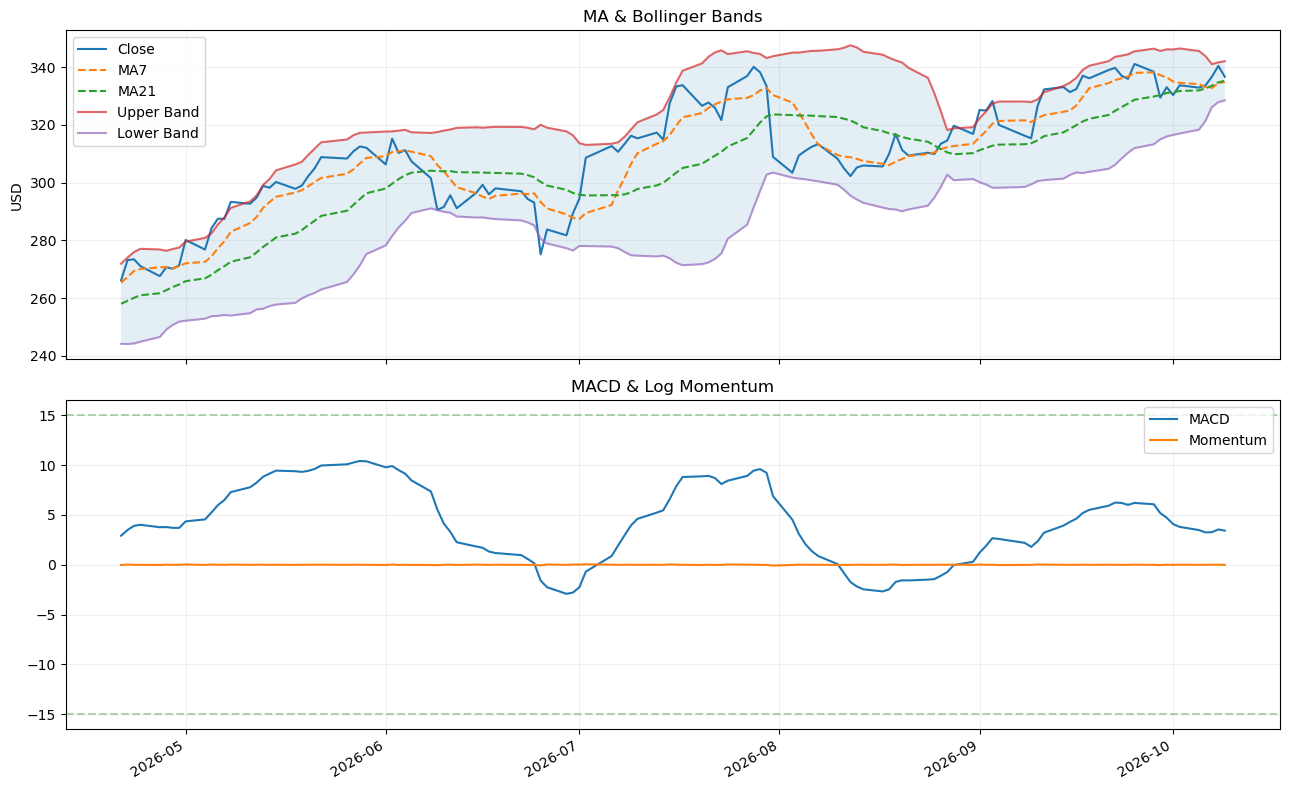

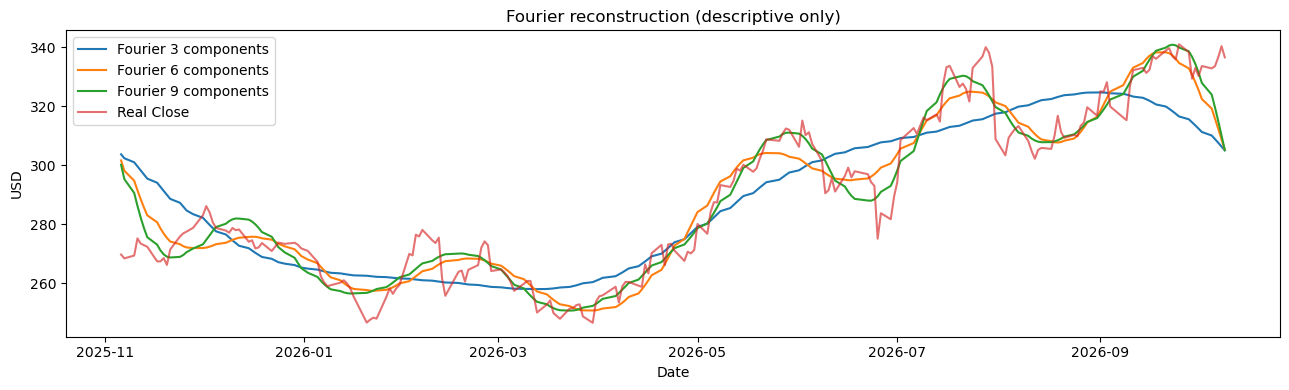

In [42]:
def plot_technical_indicators(data, last_days=120):
    d = data.tail(last_days).copy()
    fig, (ax1,ax2) = plt.subplots(2,1,figsize=(13,8),sharex=True)
    ax1.plot(d.Date,d.Close,label='Close');ax1.plot(d.Date,d.MA7,'--',label='MA7')
    ax1.plot(d.Date,d.MA21,'--',label='MA21')
    ax1.plot(d.Date,d.upper_band,label='Upper Band',alpha=.7)
    ax1.plot(d.Date,d.lower_band,label='Lower Band',alpha=.7)
    ax1.fill_between(d.Date,d.lower_band,d.upper_band,alpha=.12)
    ax1.set_title('MA & Bollinger Bands');ax1.set_ylabel('USD');ax1.legend();ax1.grid(alpha=.2)
    ax2.plot(d.Date,d.MACD,label='MACD');ax2.plot(d.Date,d.logmomentum,label='Momentum')
    ax2.axhline(15,color='g',ls='--',alpha=.3);ax2.axhline(-15,color='g',ls='--',alpha=.3)
    ax2.set_title('MACD & Log Momentum');ax2.legend();ax2.grid(alpha=.2)
    fig.autofmt_xdate();plt.tight_layout();plt.show()

def plot_Fourier(data):
    fft = np.fft.fft(data.Close.to_numpy(dtype=float))
    fig,ax = plt.subplots(figsize=(13,4))
    for k in [3,6,9]:
        c = fft.copy();c[k:-k]=0
        ax.plot(data.Date,np.fft.ifft(c).real,label=f'Fourier {k} components')
    ax.plot(data.Date,data.Close,label='Real Close',alpha=.65)
    ax.set(xlabel='Date',ylabel='USD',title='Fourier reconstruction (descriptive only)')
    ax.legend();plt.tight_layout();plt.show()

plot_technical_indicators(T_df,120)
plot_Fourier(dataset)


## 6 · Merge the provided FinBERT-scored news by publication date

In [43]:
if not NEWS_FILE.exists():
    raise FileNotFoundError(f"FinBERT news file missing: {NEWS_FILE}")

news = pd.read_csv(NEWS_FILE)

news = news.rename(columns={"P_positive": "positive","P_negative": "negative","P_neutral": "neutral","Score": "sentiment_score"
})

needed_news = {"Published At UTC","positive","negative","neutral","sentiment_score"}

if not needed_news.issubset(news.columns):
    raise ValueError(f'News CSV missing {needed_news-set(news.columns)}')
# Explicit assumption: assign news to New York calendar date of publication.
# This is NOT a strict premarket-only feature; for next-day forecasts, use EOD features after market close.
news['News_Date'] = pd.to_datetime(news['Published At UTC'],utc=True,errors='coerce').dt.tz_convert('America/New_York').dt.tz_localize(None).dt.normalize()
for col in ['positive','negative','neutral','sentiment_score']:
    news[col] = pd.to_numeric(news[col],errors='coerce')
news = news.dropna(subset=['News_Date','sentiment_score'])
daily_news = news.groupby('News_Date',as_index=False).agg(
    Sentiment_Score=('sentiment_score','mean'), News_Count=('sentiment_score','size'),
    Positive_Mean=('positive','mean'), Negative_Mean=('negative','mean'), Neutral_Mean=('neutral','mean'))
# Map non-trading-day news to next trading day, to avoid silently dropping weekend stories.
trading_dates = prices['Date'].to_numpy(dtype='datetime64[ns]')
idx = np.searchsorted(trading_dates, daily_news.News_Date.to_numpy(dtype='datetime64[ns]'),side='left')
valid = idx < len(trading_dates)
daily_news = daily_news.loc[valid].copy()
daily_news['Date'] = pd.to_datetime(trading_dates[idx[valid]])
daily_news = daily_news.groupby('Date',as_index=False).agg(
    Sentiment_Score=('Sentiment_Score','mean'), News_Count=('News_Count','sum'),
    Positive_Mean=('Positive_Mean','mean'),Negative_Mean=('Negative_Mean','mean'),Neutral_Mean=('Neutral_Mean','mean'))
full = T_df.merge(daily_news,on='Date',how='left',validate='one_to_one')
for c in ['Sentiment_Score','News_Count','Positive_Mean','Negative_Mean','Neutral_Mean']:
    full[c] = full[c].fillna(0)
full['News_Count'] = full['News_Count'].astype(int)
full['Has_News'] = (full.News_Count>0).astype(int)
full['Sentiment_MA3'] = full.Sentiment_Score.rolling(3,min_periods=1).mean()
full['News_Count_3D'] = full.News_Count.rolling(3,min_periods=1).sum()
print('Articles:',len(news),'| Trading days with news:',full.Has_News.sum())


Articles: 795 | Trading days with news: 221


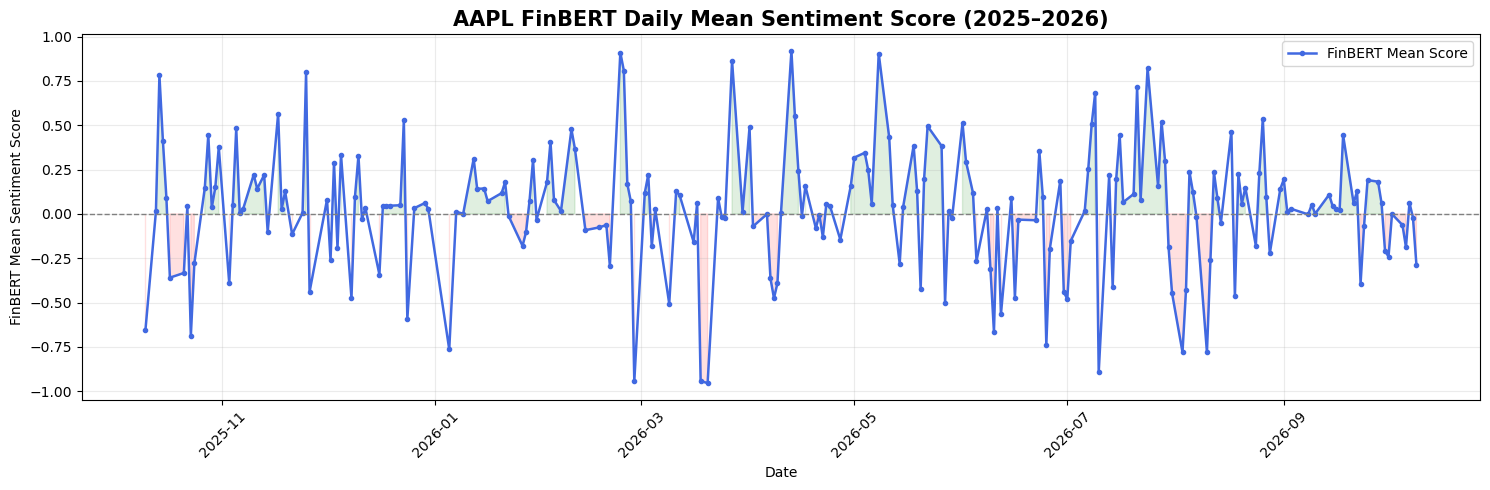

In [44]:
import matplotlib.pyplot as plt
import pandas as pd

# FinBERT Daily Mean Sentiment Score
sentiment_plot = full.loc[
    full["Has_News"] == 1,
    ["Date", "Sentiment_Score"]
].copy()

sentiment_plot = sentiment_plot.sort_values("Date")

plt.figure(figsize=(15, 5))

plt.plot(
    sentiment_plot["Date"],
    sentiment_plot["Sentiment_Score"],
    color="royalblue",
    linewidth=1.8,
    marker="o",
    markersize=3,
    label="FinBERT Mean Score"
)

plt.axhline(
    y=0,
    color="gray",
    linestyle="--",
    linewidth=1
)

plt.fill_between(
    sentiment_plot["Date"],
    sentiment_plot["Sentiment_Score"],
    0,
    where=sentiment_plot["Sentiment_Score"] >= 0,
    color="green",
    alpha=0.12
)

plt.fill_between(
    sentiment_plot["Date"],
    sentiment_plot["Sentiment_Score"],
    0,
    where=sentiment_plot["Sentiment_Score"] < 0,
    color="red",
    alpha=0.12
)

plt.title(
    "AAPL FinBERT Daily Mean Sentiment Score (2025–2026)",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("FinBERT Mean Sentiment Score")

plt.legend()
plt.grid(alpha=0.25)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 7 · Next-day targets and modeling table

**Target alignment:** features at trading day *t* predict adjusted close and log-return at the **next observed trading day** *t+1*. No target columns are fed into X. Full-data Fourier components are excluded from modeling because they would leak test-period information.

In [45]:
full['Target_Date'] = full['Date'].shift(-1)
full['Target_Next_Adj_Close'] = full['Adj_Close'].shift(-1)
full['Target_Next_Log_Return'] = np.log(full['Adj_Close'].shift(-1) / full['Adj_Close'])
final_columns = ['Date','Open','High','Low','Close','Volume','Adj_Close','Log_Return',
                 'MA7','MA21','EMA12','EMA26','MACD','MACD_Signal','SD20','Volatility20',
                 'Volume_Log','RSI14','MA7_Ratio','MA21_Ratio','MACD_Ratio',
                 'Sentiment_Score','News_Count','Positive_Mean','Negative_Mean','Neutral_Mean',
                 'Has_News','Sentiment_MA3','News_Count_3D',
                 'Target_Next_Log_Return','Target_Next_Adj_Close','Target_Date']
Finaldata = full[final_columns].copy()
model_cols = ['Date','Target_Date','Adj_Close','Log_Return','MA7_Ratio','MA21_Ratio',
              'MACD_Ratio','MACD_Signal','Volatility20','RSI14','Volume_Log',
              'Sentiment_Score','News_Count','Has_News','Sentiment_MA3','News_Count_3D',
              'Target_Next_Log_Return','Target_Next_Adj_Close']
modeling = Finaldata[model_cols].replace([np.inf,-np.inf],np.nan).dropna().reset_index(drop=True)
assert modeling.Date.is_monotonic_increasing and modeling.Date.is_unique
assert (modeling.Target_Date>modeling.Date).all()
Finaldata.to_csv(OUT/'Finaldata_2025_2026.csv',index=False)
modeling.to_csv(OUT/'AAPL_GAN_modeling_2025_2026.csv',index=False)
print('Finaldata:',Finaldata.shape,'| GAN modeling:',modeling.shape)
display(modeling.head())


Finaldata: (252, 32) | GAN modeling: (231, 18)


,Date,Target_Date,Adj_Close,Log_Return,MA7_Ratio,MA21_Ratio,MACD_Ratio,MACD_Signal,Volatility20,RSI14,Volume_Log,Sentiment_Score,News_Count,Has_News,Sentiment_MA3,News_Count_3D,Target_Next_Log_Return,Target_Next_Adj_Close
0,2025-11-06,2025-11-07,268.777130,-0.001371,-0.001100,0.034175,0.016867,3.802399,0.014828,30.234723,17.751328,0.005258,2,1,0.178480,7.0,-0.004831,267.481903
1,2025-11-07,2025-11-10,267.481903,-0.004831,-0.005267,0.026487,0.016150,3.905899,0.012006,29.408392,17.691438,0.029864,1,1,0.172317,5.0,0.004538,268.698578
2,2025-11-10,2025-11-11,268.698578,0.004538,0.000163,0.026592,0.015632,3.964781,0.011944,31.307590,17.536673,0.221078,1,1,0.085400,4.0,0.021371,274.502808
3,2025-11-11,2025-11-12,274.502808,0.021371,0.018989,0.043499,0.016473,4.076179,0.012496,39.649287,17.648670,0.142008,1,1,0.130983,3.0,-0.006488,272.727661
4,2025-11-12,2025-11-13,272.727661,-0.006488,0.009899,0.031918,0.016795,4.177040,0.012767,38.124450,17.694969,0.000000,0,0,0.121029,2.0,-0.001903,272.209076


## 8 · Chronological train/test split, train-only scalers, sliding windows

The reference GAN script expects `X_train.npy`, `y_train.npy`, `X_test.npy`, `y_test.npy`, `yc_train.npy`, `yc_test.npy` plus scaler files. Here **X** has shape `(samples, LOOKBACK, features)`, **y** has shape `(samples, 1)`, and **yc** has shape `(samples, 3, 1)` so its discriminator can concatenate y with yc into four steps. The three yc values are *historical adjusted closes* known at prediction time (scaled with the target scaler); no future target is used as input. For predicting next-day **price**, use `Target_Next_Adj_Close`.

In [46]:
FEATURE_COLUMNS = ['Adj_Close','Log_Return','MA7_Ratio','MA21_Ratio','MACD_Ratio',
                   'MACD_Signal','Volatility20','RSI14','Volume_Log','Sentiment_Score',
                   'News_Count','Has_News','Sentiment_MA3','News_Count_3D']
TARGET_COLUMN = 'Target_Next_Adj_Close'
N = len(modeling)
cut = int(N*(1-TEST_FRACTION))
if cut <= LOOKBACK + 3 or N-cut < 1: raise ValueError('Not enough data for requested lookback/split')
X_scaler = StandardScaler().fit(modeling.iloc[:cut][FEATURE_COLUMNS])
y_scaler = StandardScaler().fit(modeling.iloc[:cut][[TARGET_COLUMN]])
X_scaled = X_scaler.transform(modeling[FEATURE_COLUMNS]).astype('float32')
# yc must use the SAME scale as the next-close target.
close_scaled = y_scaler.transform(modeling[['Adj_Close']].rename(columns={'Adj_Close':TARGET_COLUMN})).astype('float32').ravel()
y_scaled = y_scaler.transform(modeling[[TARGET_COLUMN]]).astype('float32')

X_train=[];X_test=[];y_train=[];y_test=[];yc_train=[];yc_test=[];index_train=[];index_test=[]
for i in range(LOOKBACK-1,N):
    x = X_scaled[i-LOOKBACK+1:i+1]
    y = y_scaled[i]
    yc = close_scaled[i-2:i+1].reshape(3,1) # historical closes at t-2,t-1,t
    if len(yc)!=3: continue
    if i<cut:
        X_train.append(x);y_train.append(y);yc_train.append(yc);index_train.append(i)
    else:
        X_test.append(x);y_test.append(y);yc_test.append(yc);index_test.append(i)

arrays = dict(X_train=np.asarray(X_train,dtype='float32'), X_test=np.asarray(X_test,dtype='float32'),
              y_train=np.asarray(y_train,dtype='float32').reshape(-1,1),
              y_test=np.asarray(y_test,dtype='float32').reshape(-1,1),
              yc_train=np.asarray(yc_train,dtype='float32'),yc_test=np.asarray(yc_test,dtype='float32'),
              index_train=np.asarray(index_train),index_test=np.asarray(index_test))
for name,arr in arrays.items(): np.save(OUT/f'{name}.npy',arr)
with open(OUT/'X_scaler.pkl','wb') as f:pickle.dump(X_scaler,f)
with open(OUT/'y_scaler.pkl','wb') as f:pickle.dump(y_scaler,f)
metadata = {'symbol':SYMBOL,'start_date':START_DATE,'end_date':END_DATE,'price_source':SOURCE,
            'lookback':LOOKBACK,'train_rows':cut,'test_rows':N-cut,'features':FEATURE_COLUMNS,
            'target':TARGET_COLUMN,'yc':'previous 3 adjusted closes (scaled by y_scaler)',
            'X_shape':list(arrays['X_train'].shape),'y_shape':list(arrays['y_train'].shape),
            'yc_shape':list(arrays['yc_train'].shape),
            'notes':'Full-series FFT exploratory only; EOD sentiment timing assumption; no trained GAN weights.'}
(OUT/'metadata.json').write_text(json.dumps(metadata,indent=2,ensure_ascii=False))
for name,arr in arrays.items():print(name,arr.shape)
print('Saved outputs to:',OUT.resolve())


X_train (165, 20, 14)
X_test (47, 20, 14)
y_train (165, 1)
y_test (47, 1)
yc_train (165, 3, 1)
yc_test (47, 3, 1)
index_train (165,)
index_test (47,)
Saved outputs to: /Users/my/Desktop/TWO-LSTM/FinBert_LSTMGRU_GAN/finbert/notebooks/gan_ready


## 9 · Sanity checks and visual review

All basic data and leakage checks passed.


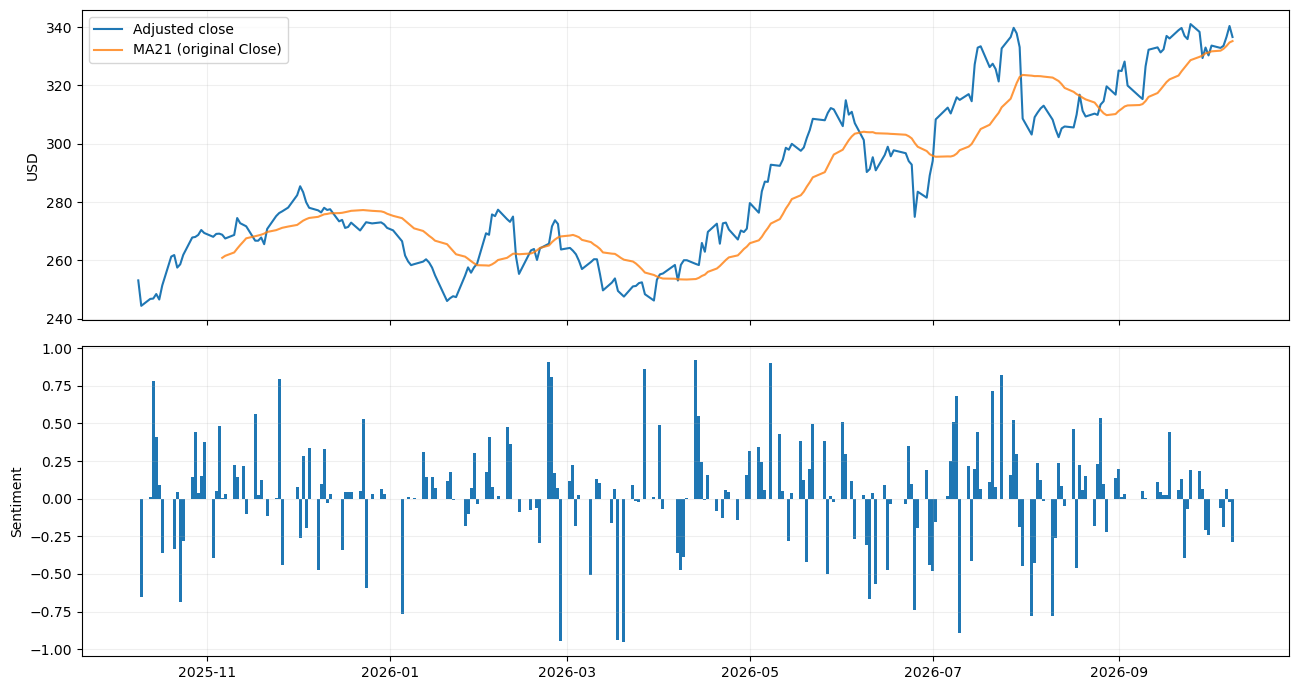

In [47]:
assert arrays['X_train'].shape[1:] == (LOOKBACK,len(FEATURE_COLUMNS))
assert arrays['yc_train'].shape[1:] == (3,1)
assert arrays['y_train'].shape[1:] == (1,)
assert np.isfinite(arrays['X_train']).all() and np.isfinite(arrays['X_test']).all()
assert np.isfinite(arrays['y_train']).all() and np.isfinite(arrays['y_test']).all()
assert max(index_train)<min(index_test)
assert not set(FEATURE_COLUMNS).intersection({'Target_Date','Target_Next_Log_Return','Target_Next_Adj_Close'})
print('All basic data and leakage checks passed.')
fig,axes=plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(Finaldata.Date,Finaldata.Adj_Close,label='Adjusted close')
axes[0].plot(Finaldata.Date,Finaldata.MA21,label='MA21 (original Close)',alpha=.8)
axes[0].legend();axes[0].set_ylabel('USD');axes[0].grid(alpha=.2)
axes[1].bar(Finaldata.Date,Finaldata.Sentiment_Score,width=1.0,label='FinBERT sentiment')
axes[1].set_ylabel('Sentiment');axes[1].grid(alpha=.2)
plt.tight_layout();plt.show()


## 10 · GAN handoff

Run the GAN training notebook from the `gan_ready/` folder or update its file paths to point there. Your original GAN notebook **also requires code adjustments** (e.g., output shapes/dtypes and optimizer compatibility) before training; generating these arrays does **not** mean the GAN has been trained. A separate notebook must train the model and save its weights.

**Cautions:** The original Fourier reconstruction uses all dates and is intentionally not in GAN inputs. Same-day news is grouped by New York publication calendar date, not verified to have been available by 4pm; for strict real-time backtesting, timestamp-filter or lag news by one session. The offline fallback uses only original OHLCV columns, not its precomputed features.